# Task 3: Ingredient Completion on Food.com

**Question:** given a *partial* list of ingredients, can we predict which ingredient is missing?

**Why it matters**
* **Recipe-writing autocomplete.** Every recipe on Food.com is typed in by a user. While they enter ingredients, the site could suggest *"did you forget baking powder?"*, like word suggestions on a phone keyboard.
* **"What's in my fridge?"** A user has only a few ingredients (eggs, flour, milk); the system suggests what else to add or buy.

This is an **item-to-item recommendation** problem: ingredients play the role of *items* and a recipe plays the role of a *shopping basket*, exactly like Amazon's "frequently bought together".

Sections follow the assignment rubric:
1. Predictive task, evaluation, baselines
2. Data, exploratory analysis and pre-processing
3. Modeling
4. Evaluation
5. Related work

In [1]:
import ast, re, random, time, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from gensim.models import Word2Vec
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

from pathlib import Path

# Data lives in the repo's dataset/ folder (not committed to git).
# This works both from scratch/<name>.ipynb (../dataset) and from workbook.ipynb at the repo root (dataset).
DATA_DIR = next((p for p in [Path("dataset"), Path("../dataset")] if (p / "RAW_recipes.csv").exists()), None)
assert DATA_DIR is not None, "Put RAW_recipes.csv and ingr_map.pkl in the repo's dataset/ folder"
SEED = 0
np.random.seed(SEED); random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Predictive task

**Input:** a set $S$ of ingredients from one recipe (the *context*).
**Output:** a ranking of all candidate ingredients $c \notin S$; the missing ingredient should be ranked as high as possible.

**How we create labels.** The dataset only contains *complete* recipes, so we simulate the missing ingredient: for every test recipe we hide one ingredient at random and ask the model to recover it (*leave-one-out*, the same protocol commonly used to evaluate recommender systems).

**Evaluation.** This is a ranking problem and a real interface shows only a handful of suggestions, so we report:
* **Hit@10**: fraction of test recipes where the hidden ingredient is in the top 10 suggestions
* **Hit@1**: the very first suggestion is correct
* **MRR** (mean reciprocal rank): rewards ranking the answer near the top

**Baselines.** Popularity (always suggest the most common ingredients), then increasingly informed co-occurrence models (Section 3).

**Validity checks.**
* Train / validation / test are split **by recipe**: test recipes are never seen when computing any statistics or training any model.
* We report bootstrap confidence intervals, a harder "non-staple" variant (Section 4.2), and look at concrete examples to make sure predictions are sensible.

## 2. Data and exploratory analysis

**Source.** Food.com (formerly GeniusKitchen) recipes, scraped by Majumder et al. (EMNLP 2019) for personalized recipe generation. `RAW_recipes.csv` has one row per recipe with its name, tags, nutrition, steps and **ingredient list**. Unlike Tasks 1 and 2 we do **not** use users, ratings or reviews: only which ingredients appear together.

We also use `ingr_map.pkl`, released with the dataset, which maps ~11.6k raw ingredient strings to a canonical name (e.g. *"romaine lettuce leaf"* → *"lettuce"*).

In [2]:
ic_raw = pd.read_csv(f"{DATA_DIR}/RAW_recipes.csv")
ingr_map = pd.read_pickle(f"{DATA_DIR}/ingr_map.pkl")
print("recipes:", ic_raw.shape)
print("ingredient map entries:", ingr_map.shape)
ic_raw[["name", "tags", "ingredients", "n_ingredients"]].head(3)

recipes: (231637, 12)
ingredient map entries: (11659, 7)


,name,tags,ingredients,n_ingredients
0,arriba baked winter squash mexican style,"['60-minutes-or-less', 'time-to-make', 'course...","['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,"['30-minutes-or-less', 'time-to-make', 'course...","['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,"['time-to-make', 'course', 'preparation', 'mai...","['ground beef', 'yellow onions', 'diced tomato...",13


### 2.1 Cleaning ingredient names

Raw ingredient strings have many spellings of the same thing, so we canonicalise them in three steps:

1. **Apply the authors' map** (`raw_ingr → replaced`).
2. **Fix a bug in the map.** While inspecting it we found that every *flour* was replaced by the nonsense word **"flmy"** (a substring replacement of "our" → "my" was applied inside words). We undo this.
3. **Merge a few remaining duplicates by hand** (e.g. *unsalted butter → butter*, *garlic clove → garlic*).

In [3]:
# Evidence of the bug in the released map
ingr_map[ingr_map.replaced.str.contains("flmy")][["raw_ingr", "replaced"]].head(6)

,raw_ingr,replaced
735,bob's red mill gluten-free all-purpose baking ...,all-purpose baking flmy
1579,whole wheat bread machine flour,whole wheat flmy
1580,organic whole wheat flour,whole wheat flmy
1581,whole wheat flour,whole wheat flmy
2089,stone ground whole wheat flour,stone ground whole wheat flmy
2170,pillsbury best all purpose flour,all purpose flmy


In [4]:
raw_to_canon = dict(zip(ingr_map.raw_ingr, ingr_map.replaced))

MANUAL_MERGE = {
    "all-purpose flour": "flour", "all purpose flour": "flour", "plain flour": "flour",
    "unbleached all-purpose flour": "flour", "unbleached flour": "flour",
    "unsalted butter": "butter", "salted butter": "butter",
    "garlic clove": "garlic",
    "vanilla extract": "vanilla", "pure vanilla extract": "vanilla",
    "black pepper": "pepper", "ground black pepper": "pepper", "fresh ground black pepper": "pepper",
    "fresh ground pepper": "pepper", "ground pepper": "pepper",
    "kosher salt": "salt", "sea salt": "salt", "table salt": "salt",
    "granulated sugar": "sugar", "white sugar": "sugar",
    "extra virgin olive oil": "olive oil",
    "ground cinnamon": "cinnamon", "ground nutmeg": "nutmeg", "ground cumin": "cumin", "ground ginger": "ginger",
    "fresh parsley": "parsley", "fresh lemon juice": "lemon juice",
}

def canonical(ingredient):
    name = raw_to_canon.get(ingredient, ingredient)
    name = re.sub(r"flmy\b", "flour", name)          # undo the "flmy" bug
    return MANUAL_MERGE.get(name, name)

ic_raw["ings"] = (ic_raw["ingredients"].map(ast.literal_eval)
                  .map(lambda lst: list(dict.fromkeys(canonical(i) for i in lst))))   # dedupe, keep order

n_before = len({i for lst in ic_raw["ingredients"].map(ast.literal_eval) for i in lst})
n_after = len({i for lst in ic_raw["ings"] for i in lst})
print(f"distinct ingredient strings: {n_before:,} -> {n_after:,} after cleaning")

distinct ingredient strings: 14,942 -> 11,256 after cleaning


### 2.2 Train / validation / test split and vocabulary

* **80 / 10 / 10 split by recipe.** Train is used to compute all co-occurrence statistics and embeddings; validation is used only to fit the learned re-ranker (Section 3.5); test is used only for the final evaluation.
* **Vocabulary = the 1,000 most frequent ingredients in the training set.** Rarer ingredients are dropped from recipes (Section 2.3 shows this keeps ~90% of all ingredient occurrences).
* We keep recipes that still have **at least 3** vocabulary ingredients, so that after hiding one there are ≥2 ingredients of context.

In [5]:
VOCAB_SIZE = 1000
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(ic_raw))
n = len(ic_raw)
split = np.empty(n, dtype=object)
split[perm[: int(0.8 * n)]] = "train"
split[perm[int(0.8 * n): int(0.9 * n)]] = "valid"
split[perm[int(0.9 * n):]] = "test"
ic_raw["split"] = split

train_counts = collections.Counter(i for lst in ic_raw.loc[ic_raw.split == "train", "ings"] for i in lst)
vocab = [ing for ing, _ in train_counts.most_common(VOCAB_SIZE)]
ing2id = {ing: k for k, ing in enumerate(vocab)}

ic_raw["ids"] = ic_raw["ings"].map(lambda lst: [ing2id[i] for i in lst if i in ing2id])
ic_recipes = ic_raw[ic_raw["ids"].map(len) >= 3].copy()

ic_train = ic_recipes[ic_recipes.split == "train"]
ic_valid = ic_recipes[ic_recipes.split == "valid"]
ic_test = ic_recipes[ic_recipes.split == "test"]
print(f"kept {len(ic_recipes):,} of {len(ic_raw):,} recipes")
print(f"train {len(ic_train):,} | valid {len(ic_valid):,} | test {len(ic_test):,}")

kept 222,709 of 231,637 recipes
train 178,206 | valid 22,209 | test 22,294


### 2.3 Exploratory analysis

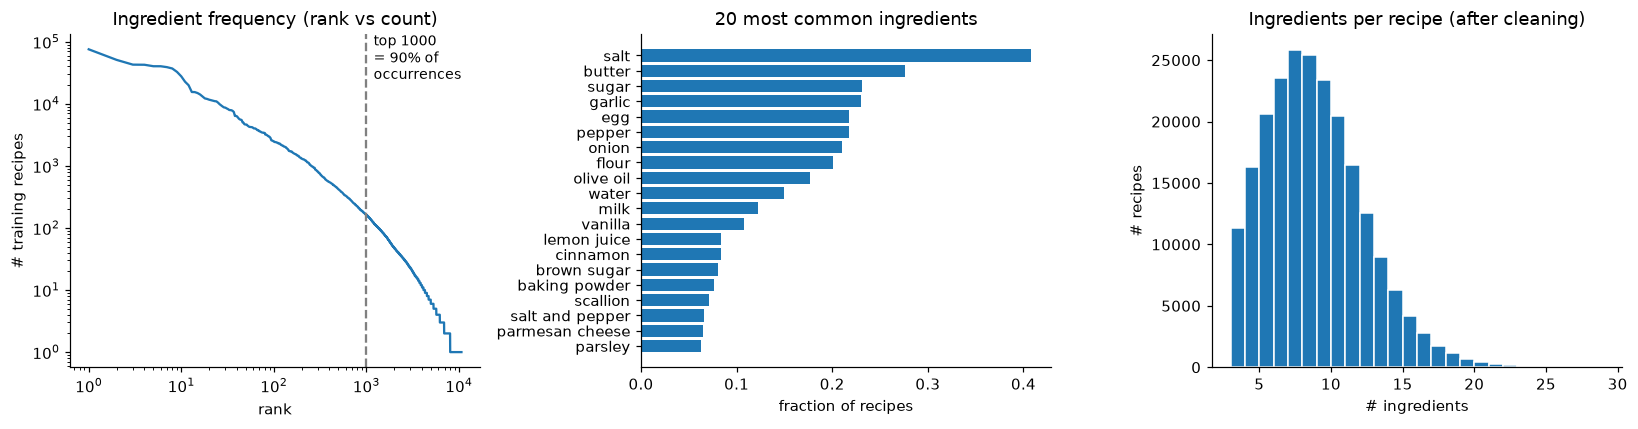

median ingredients per recipe: 8


In [6]:
freq = np.array(sorted(train_counts.values(), reverse=True))
coverage = freq[:VOCAB_SIZE].sum() / freq.sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].loglog(np.arange(1, len(freq) + 1), freq)
axes[0].axvline(VOCAB_SIZE, ls="--", c="gray")
axes[0].set(title="Ingredient frequency (rank vs count)", xlabel="rank", ylabel="# training recipes")
axes[0].text(VOCAB_SIZE * 1.2, freq[0] / 3, f"top {VOCAB_SIZE}\n= {coverage:.0%} of\noccurrences", fontsize=9)

top = train_counts.most_common(20)[::-1]
axes[1].barh([t[0] for t in top], [t[1] / len(ic_raw[ic_raw.split == "train"]) for t in top])
axes[1].set(title="20 most common ingredients", xlabel="fraction of recipes")

axes[2].hist(ic_recipes["ids"].map(len), bins=range(3, 30), edgecolor="white")
axes[2].set(title="Ingredients per recipe (after cleaning)", xlabel="# ingredients", ylabel="# recipes")
plt.tight_layout(); plt.show()
print(f"median ingredients per recipe: {ic_recipes['ids'].map(len).median():.0f}")

**Take-aways**
* Ingredient frequency is extremely **long-tailed**: a few staples (salt, butter, sugar, garlic, egg) appear in 20–40% of recipes. A popularity baseline will therefore be strong, and a good model must do better than "always suggest salt".
* The top 1,000 ingredients cover about 90% of all ingredient occurrences, so the vocabulary cut loses little.
* A typical recipe has ~8 ingredients, so after hiding one there is usually plenty of context.

Recipes also come with **tags**. We map each recipe to one *course* (first matching tag from a fixed list); we will use it later as extra context.

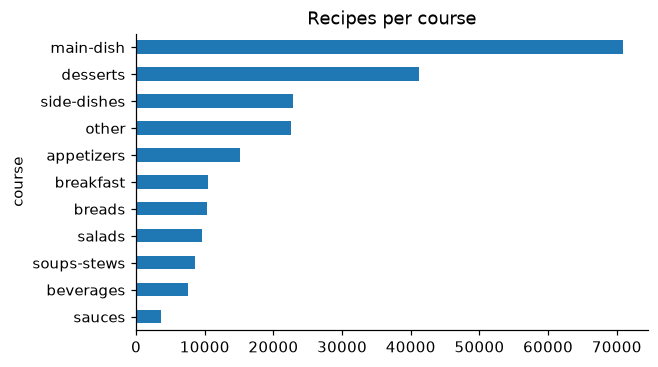

In [7]:
COURSES = ["desserts", "main-dish", "side-dishes", "appetizers", "breakfast", "salads",
           "soups-stews", "beverages", "breads", "sauces"]

def recipe_course(tags):
    for c in COURSES:
        if f"'{c}'" in tags:
            return c
    return "other"

ic_recipes["course"] = ic_recipes["tags"].map(recipe_course)
ic_train = ic_recipes[ic_recipes.split == "train"]
ic_valid = ic_recipes[ic_recipes.split == "valid"]
ic_test = ic_recipes[ic_recipes.split == "test"]
ic_recipes["course"].value_counts().plot.barh(figsize=(6, 3.5), title="Recipes per course");
plt.gca().invert_yaxis(); plt.show()

### 2.4 Which ingredients go together?

We build the ingredient–ingredient **co-occurrence matrix** from the training recipes: entry $(i, j)$ counts recipes containing both $i$ and $j$. This is computed as $X^\top X$ where $X$ is the sparse recipe × ingredient matrix.

In [8]:
rows = np.repeat(np.arange(len(ic_train)), ic_train["ids"].map(len))
cols = np.concatenate(ic_train["ids"].values)
X_train = sparse.csr_matrix((np.ones(len(cols)), (rows, cols)), shape=(len(ic_train), VOCAB_SIZE))

cooc = (X_train.T @ X_train).toarray()
pop = np.diag(cooc).copy()            # number of training recipes containing each ingredient
np.fill_diagonal(cooc, 0)
N_TRAIN = len(ic_train)

def top_pairs(M, k=10, min_count=0):
    M = np.triu(M, 1).copy()
    M[np.triu(cooc, 1) < min_count] = 0
    flat = np.argsort(-M, axis=None)[:k]
    return pd.DataFrame([(vocab[i], vocab[j], int(cooc[i, j]), round(float(M[i, j]), 2))
                         for i, j in zip(*np.unravel_index(flat, M.shape))],
                        columns=["ingredient A", "ingredient B", "co-occurrences", "score"])

top_pairs(cooc.astype(float))

,ingredient A,ingredient B,co-occurrences,score
0,salt,pepper,30525,30525.0
1,salt,butter,25815,25815.0
2,salt,flour,24890,24890.0
3,salt,sugar,23157,23157.0
4,salt,egg,23081,23081.0
5,butter,flour,21603,21603.0
6,egg,flour,20185,20185.0
7,salt,garlic,19912,19912.0
8,butter,egg,19474,19474.0
9,sugar,egg,18775,18775.0


Raw counts are dominated by staples (*salt + pepper*, *butter + sugar*). Pointwise mutual information (PMI) instead asks whether two ingredients co-occur **more often than chance**:
$$\text{PMI}(i,j) = \log \frac{P(i,j)}{P(i)P(j)} = \log\frac{\text{cooc}_{ij}\, N}{\text{pop}_i\,\text{pop}_j}$$
The highest-PMI pairs are classic pairings that raw counts would never surface:

In [9]:
with np.errstate(divide="ignore"):
    pmi = np.log(np.maximum(cooc, 1e-12) * N_TRAIN / np.outer(pop, pop))
ppmi = np.maximum(pmi, 0)
ppmi[cooc < 5] = 0          # ignore pairs seen fewer than 5 times (PMI is unreliable for rare pairs)

top_pairs(ppmi, min_count=50)

,ingredient A,ingredient B,co-occurrences,score
0,xanthan gum,potato starch,68,5.71
1,turmeric powder,coriander powder,110,5.37
2,rice flour,xanthan gum,81,5.31
3,red chili powder,turmeric powder,115,5.18
4,cumin powder,coriander powder,86,5.15
5,mirin,sake,58,5.14
6,red chili powder,coriander powder,89,5.11
7,tequila,triple sec,128,5.04
8,dried oregano leaf,dried basil leaf,52,5.00
9,turmeric powder,curry leaf,57,4.99


## 3. Modeling

All models produce a score for every candidate ingredient $c$ given the context $S$; we rank by score and exclude ingredients already in $S$. The first four are *neighbourhood (similarity-based)* models:
$$\text{score}(c \mid S) = \sum_{s \in S} \text{sim}(c, s)$$
They differ only in the definition of $\text{sim}$. The fifth model *learns* how to combine them.

| Model | sim(c, s) | Pros | Cons |
|---|---|---|---|
| Popularity | ignores $S$; score = frequency of $c$ | trivial, strong on staples | not context-aware |
| Co-occurrence | # recipes with both | simple, intuitive | biased towards popular items |
| Jaccard | cooc / (pop$_c$ + pop$_s$ − cooc) | normalises for popularity (course item-to-item method) | noisy for rare items |
| PPMI | positive PMI | finds *specific* pairings | over-promotes rare items |
| item2vec | learned embeddings | captures indirect relationships, compact | hyper-parameters, less interpretable |
| **LR re-ranker** | learned combination of all signals + course | uses every signal; interpretable weights | needs extra data (validation split), two stages |

In [10]:
jaccard = cooc / (pop[:, None] + pop[None, :] - cooc)
np.fill_diagonal(jaccard, 0)

### 3.1 item2vec

Following Barkan & Koenigstein (2016), we train **word2vec (skip-gram, negative sampling)** treating each recipe's ingredient list as a "sentence". Ingredient order is meaningless, so we shuffle each list and use a window (50) larger than any recipe, making every ingredient in a recipe context for every other one. We disable frequent-word down-sampling (`sample=0`) because the popularity of staples is useful signal here, and train single-threaded with a fixed seed so results are reproducible.

Skip-gram learns **two** vectors per ingredient: an *input* vector $v_i$ and an *output* (context) vector $u_i$. This gives two natural similarity measures, and they behave very differently:
* **Cosine of input vectors** $\cos(v_c, v_s)$: high when two ingredients appear *in similar recipes* → they are **substitutes** (butter ↔ margarine).
* **Input · output** $v_s^\top u_c$: what skip-gram is actually trained to predict, i.e. how likely $c$ appears *in the same recipe* as $s$ → **complements** (flour → baking powder).

In [11]:
t0 = time.time()
shuffle_rng = random.Random(SEED)
sentences = []
for ids in ic_train["ids"]:
    s = [vocab[i] for i in ids]
    shuffle_rng.shuffle(s)
    sentences.append(s)

# workers=1: single-threaded training is fully reproducible (same numbers on every re-run);
# multi-threaded training is faster but changes results slightly from run to run.
w2v = Word2Vec(sentences, vector_size=64, window=50, min_count=1, sg=1, negative=10,
               sample=0, epochs=5, workers=1, seed=SEED)

W_in = np.stack([w2v.wv[v] for v in vocab])
W_out = np.stack([w2v.syn1neg[w2v.wv.key_to_index[v]] for v in vocab])
W_in_norm = W_in / np.linalg.norm(W_in, axis=1, keepdims=True)

w2v_cos = W_in_norm @ W_in_norm.T;  np.fill_diagonal(w2v_cos, 0)   # substitutes
w2v_io = W_in @ W_out.T;            np.fill_diagonal(w2v_io, 0)    # complements
print(f"trained in {time.time() - t0:.0f}s")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


trained in 101s


### 3.2 Learned re-ranker (logistic regression)

Each similarity captures a different signal, so we let a model learn how to weigh them. Following the standard two-stage recommender design:

1. **Candidate generation:** take the top-100 candidates by Jaccard score.
2. **Re-ranking:** a logistic regression predicts $P(c \text{ is the missing ingredient})$ from 7 features of the (context, candidate) pair:
   * log popularity of $c$
   * mean co-occurrence, Jaccard, PPMI, item2vec cosine and item2vec input·output similarity between $c$ and $S$
   * **course prior**: log-frequency of $c$ among training recipes of the same course (desserts, main-dish, ...), using the recipe's tags, which are known while the recipe is being written

**Training data** comes from the **validation** recipes (not the training recipes, whose own co-occurrences are already baked into the similarity matrices, which would leak the answer). For each validation recipe we hide one ingredient, generate the 100 candidates, and label the hidden one 1 and the others 0.

In [12]:
course_logprob = {}
for course, grp in ic_train.groupby("course"):
    counts = np.zeros(VOCAB_SIZE)
    for ids in grp["ids"]:
        counts[ids] += 1
    course_logprob[course] = np.log((counts + 1) / (len(grp) + VOCAB_SIZE))
log_pop = np.log(pop / N_TRAIN)

FEATURE_NAMES = ["log popularity", "log co-occurrence", "Jaccard", "PPMI",
                 "item2vec cosine (substitute)", "item2vec in·out (complement)", "course prior"]

def features(ctx, course):
    # (VOCAB_SIZE x 7) feature matrix: one row per candidate ingredient
    return np.stack([log_pop,
                     np.log1p(cooc[ctx].mean(0)),
                     jaccard[ctx].mean(0),
                     ppmi[ctx].mean(0),
                     w2v_cos[ctx].mean(0),
                     w2v_io[ctx].mean(0),
                     course_logprob[course]], axis=1)

N_CANDIDATES = 100

def candidates(ctx):
    s = jaccard[ctx].sum(0)
    s[ctx] = -np.inf
    return np.argsort(-s)[:N_CANDIDATES]

def hide_one(ids, rnd):
    target = rnd.choice(ids)
    return [i for i in ids if i != target], target

rnd = random.Random(SEED + 1)
X_rr, y_rr, covered = [], [], 0
valid_sample = ic_valid.sample(10000, random_state=SEED)
for ids, course in zip(valid_sample["ids"], valid_sample["course"]):
    ctx, target = hide_one(ids, rnd)
    cand = candidates(ctx)
    if target not in cand:          # no positive example available for this recipe
        continue
    covered += 1
    X_rr.append(features(ctx, course)[cand])
    y_rr.append((cand == target).astype(int))
X_rr, y_rr = np.vstack(X_rr), np.concatenate(y_rr)
print(f"candidate recall@{N_CANDIDATES} on validation: {covered / len(valid_sample):.1%}")
print(f"re-ranker training rows: {len(y_rr):,} ({y_rr.mean():.1%} positive)")

scaler = StandardScaler().fit(X_rr)
reranker = LogisticRegression(max_iter=2000).fit(scaler.transform(X_rr), y_rr)

candidate recall@100 on validation: 79.4%
re-ranker training rows: 794,300 (1.0% positive)


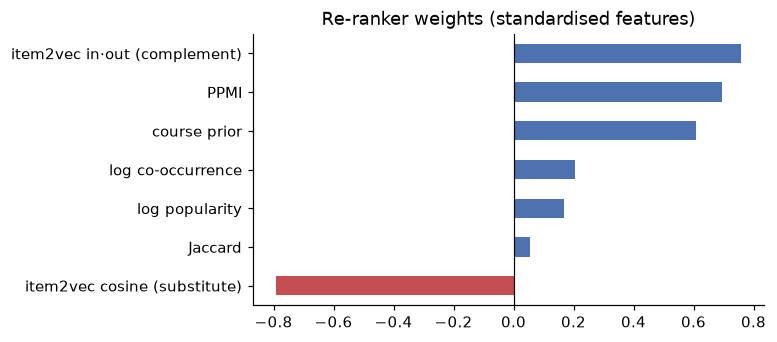

In [13]:
coefs = pd.Series(reranker.coef_[0], index=FEATURE_NAMES).sort_values()
coefs.plot.barh(figsize=(6, 3.2), color=["#c44e52" if v < 0 else "#4c72b0" for v in coefs],
                title="Re-ranker weights (standardised features)")
plt.axvline(0, c="k", lw=0.8); plt.show()

**Reading the weights.** The complement signal (item2vec input·output), PPMI and the course prior get the largest positive weights. The **substitute** signal (item2vec cosine) gets a large **negative** weight: if you already have butter, the model learns *not* to suggest margarine. This is exactly the complement-vs-substitute distinction from Section 3.1.

## 4. Evaluation

### 4.1 Main results

For 10,000 test recipes we hide one random ingredient (fixed seed, identical for all models) and rank all 1,000 candidates.

In [14]:
def lr_scores(ctx, course):
    s = np.full(VOCAB_SIZE, -1e9)
    cand = candidates(ctx)
    s[cand] = reranker.decision_function(scaler.transform(features(ctx, course)[cand]))
    return s

MODELS = {
    "Popularity":              lambda ctx, course: pop.astype(float),
    "Co-occurrence":           lambda ctx, course: cooc[ctx].sum(0),
    "Jaccard":                 lambda ctx, course: jaccard[ctx].sum(0),
    "PPMI":                    lambda ctx, course: ppmi[ctx].sum(0),
    "item2vec cosine":         lambda ctx, course: w2v_cos[ctx].sum(0),
    "item2vec in·out":         lambda ctx, course: w2v_io[ctx].sum(0),
    "LR re-ranker":            lr_scores,
}

def rank_of(scores, ctx, target):
    s = scores.astype(float).copy()
    s[ctx] = -np.inf
    return 1 + int((s > s[target]).sum())

test_sample = ic_test.sample(10000, random_state=SEED)
rnd = random.Random(SEED)
test_cases = [(*hide_one(ids, rnd), course) for ids, course in zip(test_sample["ids"], test_sample["course"])]

ranks = {name: np.array([rank_of(f(ctx, course), ctx, t) for ctx, t, course in test_cases])
         for name, f in MODELS.items()}

def summarize(rank_dict, mask=None):
    out = {}
    for name, r in rank_dict.items():
        r = r if mask is None else r[mask]
        out[name] = {"Hit@1": (r <= 1).mean(), "Hit@10": (r <= 10).mean(), "MRR": (1 / r).mean()}
    return pd.DataFrame(out).T

main_table = summarize(ranks)
main_table.style.format("{:.3f}").highlight_max(color="#cde4c3")

,Hit@1,Hit@10,MRR
Popularity,0.066,0.318,0.142
Co-occurrence,0.115,0.365,0.200
Jaccard,0.124,0.411,0.217
PPMI,0.029,0.153,0.075
item2vec cosine,0.004,0.039,0.020
item2vec in·out,0.085,0.424,0.198
LR re-ranker,0.172,0.471,0.270


**95% bootstrap confidence intervals for Hit@10** (resampling test recipes) confirm that the differences between models are not noise:

In [15]:
boot_rng = np.random.default_rng(SEED)
boot_idx = boot_rng.integers(0, len(test_cases), size=(1000, len(test_cases)))
ci = {name: np.percentile((r[boot_idx] <= 10).mean(1), [2.5, 97.5]) for name, r in ranks.items()}
pd.DataFrame(ci, index=["2.5%", "97.5%"]).T.round(3)

,2.5%,97.5%
Popularity,0.310,0.327
Co-occurrence,0.356,0.374
Jaccard,0.402,0.421
PPMI,0.147,0.161
item2vec cosine,0.035,0.043
item2vec in·out,0.414,0.434
LR re-ranker,0.461,0.481


**Observations**
* **Popularity is a strong baseline** (Hit@10 ≈ 0.32), because staples are so common.
* **Jaccard** beats raw co-occurrence by correcting for popularity; **item2vec in·out** reaches a similar Hit@10 (slightly higher) but a lower Hit@1/MRR.
* The **LR re-ranker** is best on every metric (Hit@10 ≈ 0.47, Hit@1 ≈ 0.17, MRR ≈ 0.27), and its confidence interval does not overlap with any other model's.
* **item2vec cosine is almost useless for completion** even though its embeddings are good (Section 4.5): cosine similarity finds *substitutes*, and you rarely add a substitute of something already in the recipe. The **input·output** score, which models co-occurrence directly, works well.
* **PPMI looks weak overall** because it ignores popularity, but see the next section.

### 4.2 Harder setting: non-staple ingredients

Hit@10 rewards models that guess *salt* or *butter*. A more demanding (and arguably more useful) question: **when the missing ingredient is not one of the 20 most common**, which model finds it?

In [16]:
top20 = set(np.argsort(-pop)[:20])
non_staple = np.array([t not in top20 for _, t, _ in test_cases])
print(f"{non_staple.mean():.0%} of test cases have a non-staple target")

compare = pd.concat({"all targets": main_table[["Hit@10", "MRR"]],
                     "non-staple targets": summarize(ranks, non_staple)[["Hit@10", "MRR"]]}, axis=1)
compare.style.format("{:.3f}").highlight_max(color="#cde4c3")

61% of test cases have a non-staple target


The ranking of models **changes**: popularity collapses to ~0, and the models that discount popularity (PPMI, item2vec in·out) are best. The re-ranker is slightly behind here partly because its candidate set comes from Jaccard, which favours popular items. **The choice of metric decides which model "wins"**: a product that wants helpful, non-obvious suggestions should optimise the non-staple metric (or blend the two).

### 4.3 From autocomplete to "what's in my fridge": varying the amount of context

Autocomplete has almost the whole recipe as context; the fridge scenario has only 2–3 ingredients. We take test recipes with ≥7 ingredients, fix the hidden target, and give each model only $k$ randomly chosen context ingredients.

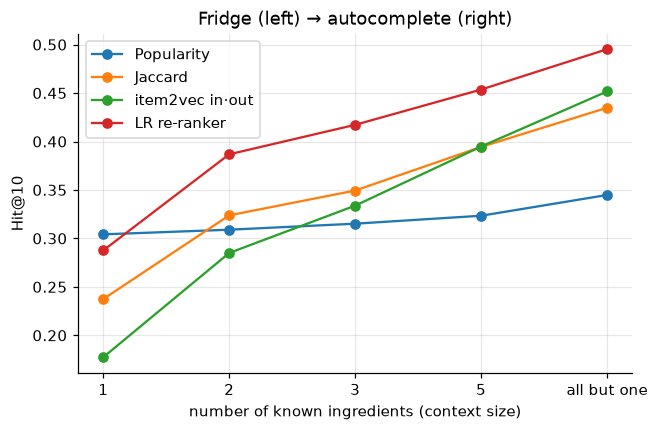

,1,2,3,5,all but one
Popularity,0.304,0.309,0.315,0.323,0.345
Jaccard,0.237,0.324,0.349,0.394,0.435
item2vec in·out,0.177,0.285,0.334,0.395,0.452
LR re-ranker,0.288,0.387,0.417,0.454,0.495


In [17]:
curve_sample = ic_test[ic_test["ids"].map(len) >= 7].sample(5000, random_state=SEED)
K_VALUES = [1, 2, 3, 5, "all"]
CURVE_MODELS = ["Popularity", "Jaccard", "item2vec in·out", "LR re-ranker"]

rnd = random.Random(SEED)
base_cases = [(*hide_one(ids, rnd), course) for ids, course in zip(curve_sample["ids"], curve_sample["course"])]

curve = {m: [] for m in CURVE_MODELS}
for k in K_VALUES:
    rnd_k = random.Random(SEED)
    cases_k = [(ctx if k == "all" else rnd_k.sample(ctx, k), t, c) for ctx, t, c in base_cases]
    for m in CURVE_MODELS:
        r = np.array([rank_of(MODELS[m](ctx, c), ctx, t) for ctx, t, c in cases_k])
        curve[m].append((r <= 10).mean())

labels = [str(k) for k in K_VALUES[:-1]] + ["all but one"]
plt.figure(figsize=(6.5, 4))
for m in CURVE_MODELS:
    plt.plot(labels, curve[m], marker="o", label=m)
plt.xlabel("number of known ingredients (context size)"); plt.ylabel("Hit@10")
plt.title("Fridge (left) → autocomplete (right)")
plt.legend(); plt.grid(alpha=0.3); plt.show()
pd.DataFrame(curve, index=labels).T.round(3)

* With **more context, every context-aware model improves** while popularity stays almost flat; the gap is largest in the autocomplete regime (right).
* With a **single** known ingredient, popularity is actually the best model: one ingredient says very little about the dish (eggs could become a cake, an omelette or pasta), and similarity scores from one item are noisy. From **two** ingredients onwards the re-ranker clearly wins.
* Design implication for a fridge assistant: fall back to (course-specific) popular items when the user has entered very little, show more suggestions, or ask a follow-up question such as which course they want to cook.

### 4.4 Results by course

In [18]:
course_arr = np.array([c for _, _, c in test_cases])
by_course = pd.DataFrame({
    m: pd.Series(ranks[m] <= 10).groupby(course_arr).mean() for m in ["Popularity", "Jaccard", "LR re-ranker"]
})
by_course["# test recipes"] = pd.Series(course_arr).value_counts()
by_course.sort_values("LR re-ranker", ascending=False).style.format(
    {c: "{:.3f}" for c in ["Popularity", "Jaccard", "LR re-ranker"]})

,Popularity,Jaccard,LR re-ranker,# test recipes
breads,0.510,0.629,0.693,463
desserts,0.438,0.533,0.591,1888
breakfast,0.393,0.498,0.578,450
beverages,0.155,0.345,0.518,328
soups-stews,0.256,0.381,0.436,367
side-dishes,0.330,0.385,0.434,1031
other,0.305,0.385,0.423,1000
salads,0.196,0.332,0.416,413
main-dish,0.280,0.358,0.409,3191
sauces,0.269,0.354,0.394,175


* Baking-style courses (breads, desserts, breakfast) are easiest: their ingredient sets are very conventional (flour, sugar, egg, baking powder, vanilla).
* Savoury courses (main dishes, appetizers, sauces, salads) are hardest: there are many more valid ways to build them.
* **Beverages** show the largest gain from context (Hit@10 from 0.16 with popularity to about 0.5 with the re-ranker): global popularity suggests salt and butter, which never appear in drinks, while the course prior and co-occurrence quickly move suggestions to juice, ice and liqueurs.

### 4.5 Qualitative examples

Top-5 suggestions of the re-ranker for a few test recipes (✓ marks the hidden ingredient):

In [19]:
def show_examples(n_examples=5, seed=3):
    rnd = random.Random(seed)
    rows = []
    for idx in rnd.sample(range(len(test_cases)), n_examples):
        ctx, t, course = test_cases[idx]
        s = lr_scores(ctx, course); s[ctx] = -np.inf
        top5 = [vocab[j] + (" ✓" if j == t else "") for j in np.argsort(-s)[:5]]
        rows.append({"recipe": test_sample.iloc[idx]["name"], "course": course,
                     "known ingredients": ", ".join(vocab[i] for i in ctx),
                     "hidden": vocab[t], "top-5 suggestions": ", ".join(top5)})
    return pd.DataFrame(rows)

pd.set_option("display.max_colwidth", 80)
show_examples()

,recipe,course,known ingredients,hidden,top-5 suggestions
0,rich double chocolate brownies,desserts,"butter, sugar, brown sugar, cocoa powder, vanilla, salt, flour, baking powde...",egg,"egg ✓, baking soda, cinnamon, milk, walnut"
1,chickpea salad balila,side-dishes,"chickpea, white onion, jalapeno, garlic, salt, cumin, lemon juice, olive oil...",parsley,"pepper, onion, butter, zucchini, water"
2,banana honey and seed loaf,breads,"toasted sesame seed, sunflower seed, olive oil, brown sugar, honey, egg, ban...",cinnamon,"salt, cinnamon ✓, flour, butter, baking powder"
3,cinnamon biscuit blossoms,side-dishes,"sugar, raspberry jam",cinnamon,"flour, butter, egg, baking powder, salt"
4,instant rice pudding,desserts,"white rice, milk, salt, vanilla, cinnamon, nutmeg",sugar,"egg, sugar ✓, flour, butter, baking powder"


* The model easily recovers **structural** ingredients of baked goods (the egg in brownies, the sugar in rice pudding).
* Misses are often still plausible: for the chickpea salad the hidden ingredient was parsley (a garnish), and the model suggests other reasonable additions such as pepper and onion.
* With only two known ingredients (*sugar, raspberry jam*) the suggestions fall back to generic baking staples, matching the context-size analysis in Section 4.3.

### 4.6 Bonus: substitutes from item2vec

Although cosine similarity was poor for completion, it is exactly what a **substitution** feature needs ("no butter? use ..."):

In [20]:
QUERY = ["butter", "sour cream", "honey", "ground beef", "milk", "rice", "chicken breast", "mozzarella"]
subs = {q: ", ".join(vocab[j] for j in np.argsort(-w2v_cos[ing2id[q]])[:6]) for q in QUERY}
pd.DataFrame.from_dict(subs, orient="index", columns=["nearest neighbours (item2vec cosine)"])

,nearest neighbours (item2vec cosine)
butter,"margarine, crisco, shortening, cooking spray, vegetable shortening, corn oil"
sour cream,"light sour cream, enchilada sauce, monterey jack pepper cheese, mexican blen..."
honey,"liquid honey, maple syrup, agave nectar, orange marmalade, pure maple syrup,..."
ground beef,"lean ground beef, ground chuck, hamburger, ground turkey, lean ground turkey..."
milk,"whole milk, skim milk, half-and-half cream, evaporated milk, half-and-half, ..."
rice,"white rice, long grain rice, cooked rice, long-grain rice, long grain white ..."
chicken breast,"chicken breast half, chicken, chicken thigh, chicken tender, cooked chicken,..."
mozzarella,"provolone cheese, pepperoni, romano cheese, marinara sauce, pizza sauce, asi..."


* Most neighbours are sensible substitutes (butter → margarine / shortening, honey → maple syrup / agave nectar, ground beef → ground turkey, mozzarella → provolone).
* Some neighbours are spelling variants that our cleaning did not merge (*rice → long grain rice*), so the embeddings could also help **clean the ingredient vocabulary** automatically.
* Cosine similarity also picks up items from the same *type of dish* (mozzarella → pizza sauce, pepperoni), so a real substitution feature would need extra filtering (e.g. penalising pairs that frequently co-occur).

### 4.7 Visualising the ingredient space

t-SNE of the item2vec embeddings for the 300 most common ingredients, coloured by the course each ingredient is most over-represented in (lift = P(ingredient | course) / P(ingredient)):

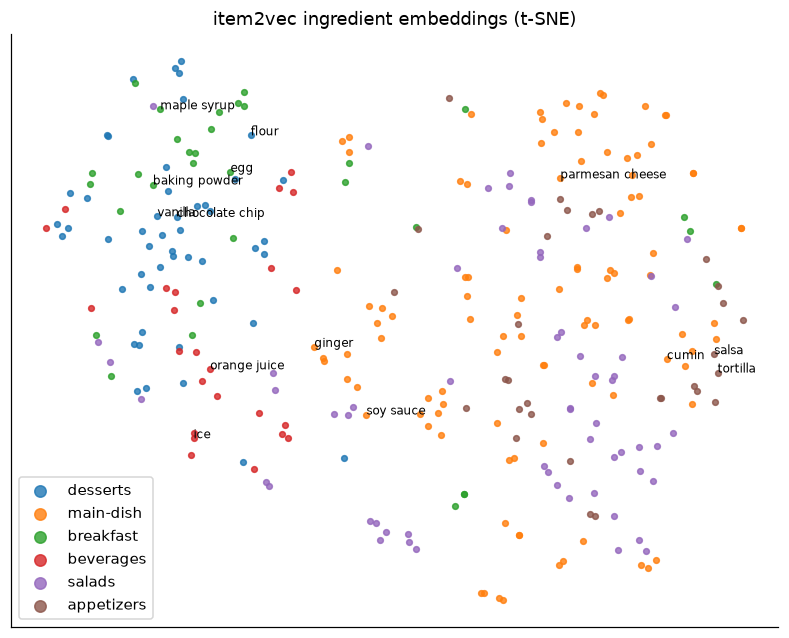

In [21]:
N_PLOT = 300
SHOW_COURSES = ["desserts", "main-dish", "breakfast", "beverages", "salads", "appetizers"]
course_rate = {c: np.exp(course_logprob[c]) for c in SHOW_COURSES}
overall_rate = pop / N_TRAIN
lift = np.stack([course_rate[c] / overall_rate for c in SHOW_COURSES], 1)
best_course = np.array(SHOW_COURSES)[lift.argmax(1)]

xy = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(W_in_norm[:N_PLOT])
plt.figure(figsize=(9, 7))
for c in SHOW_COURSES:
    m = best_course[:N_PLOT] == c
    plt.scatter(xy[m, 0], xy[m, 1], s=14, label=c, alpha=0.8)
for name in ["flour", "baking powder", "vanilla", "chocolate chip", "soy sauce", "ginger", "salsa",
             "tortilla", "orange juice", "ice", "parmesan cheese", "egg", "maple syrup", "cumin"]:
    if name in ing2id and ing2id[name] < N_PLOT:
        plt.annotate(name, xy[ing2id[name]], fontsize=8)
plt.legend(markerscale=2); plt.xticks([]); plt.yticks([])
plt.title("item2vec ingredient embeddings (t-SNE)"); plt.show()

The space splits into two large regions, **sweet** (desserts, breakfast, drinks: flour, vanilla, maple syrup) and **savoury** (main dishes, salads, appetizers), even though the model never saw any tags, only which ingredients share a recipe. Within the savoury side, Mexican (salsa, tortilla, cumin) and Asian (soy sauce, ginger) ingredients sit in their own neighbourhoods.

## 5. Related work

* **The dataset.** Majumder, Li, Ni & McAuley, *Generating Personalized Recipes from Historical User Preferences*, EMNLP 2019, collected Food.com recipes and interactions for personalized recipe *generation*. Most other uses of the data (e.g. course projects) predict ratings, cooking time or calories from recipe metadata; we instead model the **ingredient–ingredient structure**.
* **Food pairing.** Ahn, Ahnert, Bagrow & Barabási, *Flavor network and the principles of food pairing* (Scientific Reports, 2011), study which ingredients tend to be combined across cuisines using co-occurrence and shared flavour compounds; our PMI analysis (Section 2.4) is in the same spirit.
* **Ingredient networks for recommendation.** Teng, Lin & Adamic, *Recipe recommendation using ingredient networks* (WebSci 2012), build a **complement network** (from co-occurrence / PMI) and a **substitute network** (from user-suggested modifications) on Allrecipes. Our results reach a similar conclusion from a single model: input·output similarity captures complements, while embedding cosine captures substitutes.
* **Item-to-item recommendation and embeddings.** Linden, Smith & York, *Amazon.com recommendations: item-to-item collaborative filtering* (IEEE Internet Computing, 2003), motivate our co-occurrence / Jaccard models; Barkan & Koenigstein, *Item2Vec: neural item embedding for collaborative filtering* (2016), motivate treating baskets (here, recipes) as sentences for word2vec.

**Summary.** A learned combination of simple similarity signals beats every individual model on the standard metric (Hit@10 ≈ 0.47 vs 0.32 for popularity), the choice of metric (all vs non-staple targets) changes which model is best, and the same embeddings support a second feature, ingredient substitution.